# GĐ 2: THỐNG KÊ MÔ TẢ (Descriptive Statistics)

**Mục tiêu:** mô tả đặc điểm của biến Y (`pm25`) và các biến X (`temperature`, `humidity`, `wind`, `rain`) — làm nền cho GĐ 3 (kiểm định, hồi quy).

## Đọc dữ liệu

Dùng đúng file `aqi_hcm_daily.csv` 
- `matplotlib.pyplot` → vẽ biểu đồ (histogram, boxplot)
- `scipy.stats` → có sẵn hàm tính skewness, kurtosis (không phải tự viết công thức tay)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline

df = pd.read_csv(r"C:\Users\duong\projects\airvisual-data-collection\01_Data\aqi_hcm_daily.csv", parse_dates=["date"])
print(f"Da doc {len(df)} dong, {df.shape[1]} cot")
df.head()

Da doc 657 dong, 34 cot


,date,pm25,pm25_cov,temperature,temperature_cov,humidity,humidity_cov,wind,rain,month,...,so2_cams,o3_cams,o3_max_cams,pm10_cams,vn_aqi_pm25,vn_aqi_cat,qcvn_24h,vuot_qcvn,vuot_who,kem_tro_len
0,2024-11-19,31.2,29.0,28.8,29.0,57.9,29.0,8.9,0.9,11,...,18.837500,47.250000,127.0,36.466667,62,Trung binh,50,0,1,0
1,2024-11-20,36.6,100.0,28.9,100.0,54.1,100.0,13.0,1.4,11,...,18.075000,48.458333,119.0,37.441667,73,Trung binh,50,0,1,0
2,2024-11-21,42.2,100.0,28.9,100.0,53.5,100.0,8.7,6.0,11,...,21.245833,47.083333,139.0,33.850000,84,Trung binh,50,0,1,0
3,2024-11-22,38.2,100.0,28.8,100.0,54.1,100.0,8.9,0.4,11,...,21.658333,38.041667,106.0,38.687500,76,Trung binh,50,0,1,0
4,2024-11-23,37.1,100.0,28.5,100.0,53.7,100.0,10.0,0.3,11,...,18.770833,45.833333,124.0,40.954167,74,Trung binh,50,0,1,0


## 1–4. Thống kê mô tả PM2.5: trung tâm, độ phân tán, hình dạng, biểu đồ

| Nhóm | Chỉ số | Ý nghĩa ngắn |
|---|---|---|
| Trung tâm | **Mean**, **Median**, **Mode** | Mean nhạy với giá trị cực đoan, Median thì không; Mode là giá trị gặp nhiều nhất |
| Phân tán | **Range**, **IQR** (Q3 − Q1), **Variance**, **Std**, **CV** (Std/Mean) | Std về đúng đơn vị µg/m³; CV đo phân tán *tương đối* nên so được giữa biến khác đơn vị |
| Hình dạng | **Skewness**, **Kurtosis** (excess, chuẩn = 0) | Skew > 0: lệch phải (đuôi dài bên phải); Kurtosis > 0: nhọn và đuôi dày hơn phân phối chuẩn |

**Vì sao so Mean với Median?** Mean > Median rõ rệt → phân phối **lệch phải**: đa số ngày vừa phải nhưng có vài đợt ô nhiễm nặng kéo trung bình lên — dấu hiệu quen thuộc của PM2.5.

,PM2.5
Mean,32.38
Median,30.30
Mode,29.20
Min,11.30
Max,92.80
Range,81.50
Q1,24.80
Q3,38.90
IQR,14.10
Variance (ug/m3)^2,127.39


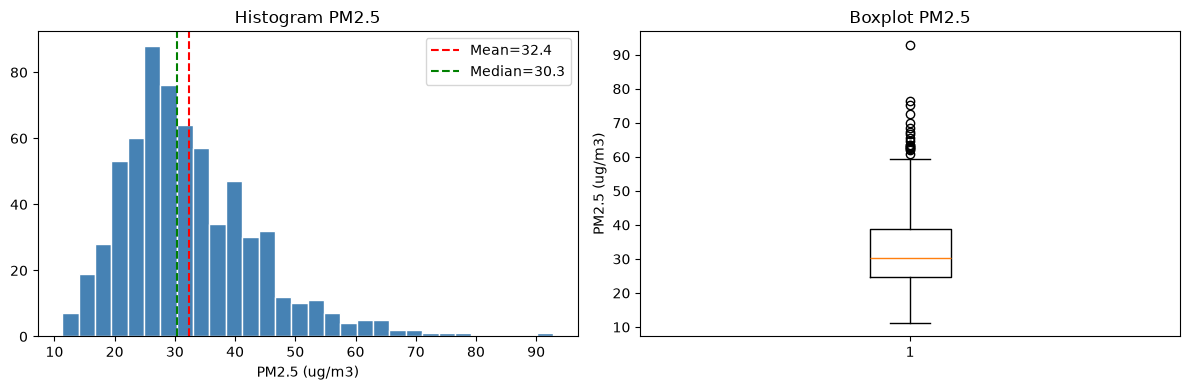

In [ ]:
pm25 = df.pm25
mean_pm25, median_pm25 = pm25.mean(), pm25.median()
q1, q3 = pm25.quantile([.25, .75])

bang = pd.Series({
    "Mean": mean_pm25, "Median": median_pm25, "Mode": pm25.mode()[0],        # mode() tra ve Series -> lay gia tri dau
    "Min": pm25.min(), "Max": pm25.max(), "Range": pm25.max() - pm25.min(),
    "Q1": q1, "Q3": q3, "IQR": q3 - q1,
    "Variance (ug/m3)^2": pm25.var(), "Std": pm25.std(), "CV (%)": pm25.std() / mean_pm25 * 100,
    "Skewness": stats.skew(pm25), "Kurtosis (excess)": stats.kurtosis(pm25),
}).round(2).to_frame("PM2.5")
display(bang)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(pm25, bins=30, color="steelblue", edgecolor="white")
ax1.axvline(mean_pm25, color="red", linestyle="--", label=f"Mean={mean_pm25:.1f}")
ax1.axvline(median_pm25, color="green", linestyle="--", label=f"Median={median_pm25:.1f}")
ax1.set_title("Histogram PM2.5"); ax1.set_xlabel("PM2.5 (ug/m3)"); ax1.legend()
ax2.boxplot(pm25)
ax2.set_title("Boxplot PM2.5"); ax2.set_ylabel("PM2.5 (ug/m3)")
plt.tight_layout()
# plt.savefig(r"C:\Users\duong\projects\airvisual-data-collection\figure\pm25.png", dpi=120)   # luu lai anh de dan vao bao cao
plt.show()


**Đọc kết quả:** Mean 32,38 > Median 30,30 (chênh 2,08) và Skewness 1,12 > 0 → phân phối **lệch phải**; Kurtosis 2,04 > 0 → nhọn, đuôi dày (có những ngày cao bất thường). Dải 11,3–92,8 µg/m³, IQR 14,1, CV 34,9%.

Phân phối PM2.5 theo ngày. Nồng độ PM2.5 trung bình là 32,38 µg/m³, cao hơn trung vị 30,30 µg/m³. Kết hợp với hệ số lệch 1,12, kết quả cho thấy phân phối lệch phải: phần lớn ngày có nồng độ ở mức thấp hơn, trong khi một số ngày PM2.5 cao làm tăng giá trị trung bình. Histogram cho thấy dữ liệu tập trung chủ yếu trong khoảng 20–40 µg/m³, nhưng vẫn có các ngày đạt mức cao; giá trị lớn nhất là 92,8 µg/m³.

Boxplot cho thấy 50% số ngày nằm trong khoảng 24,8–38,9 µg/m³ (IQR = 14,1 µg/m³). Theo quy tắc IQR, các giá trị trên 60,05 µg/m³ được đánh dấu là ngoại lai thống kê; có 18/657 ngày thuộc nhóm này. Đây là cách nhận diện các giá trị nằm xa phần lớn quan sát, không khẳng định số đo bị sai. Mốc ngoại lai thống kê cũng khác mốc phân loại chất lượng không khí: 46 ngày (7,0%) vượt 50 µg/m³ và được xếp từ mức Kém trở lên theo cách phân loại dùng trong phân tích.

In [3]:
thu_tu = ["Tot", "Trung binh", "Kem", "Xau", "Rat xau", "Nguy hai"]
ty_le = (df["vn_aqi_cat"].value_counts(normalize=True) * 100).reindex(thu_tu).fillna(0)
ty_le.round(1).to_frame("% so ngay")

,% so ngay
vn_aqi_cat,
Tot,26.6
Trung binh,66.4
Kem,6.8
Xau,0.2
Rat xau,0.0
Nguy hai,0.0


## 5. PM2.5 theo mùa và theo THÁNG — chuẩn bị cho GĐ 3 (t-test, ANOVA)

Đề bài hỏi "phân bố theo mùa". Chia 2 mùa (khô/mưa) cho con số gọn, chia 12 tháng cho thấy **tháng nào đỉnh, tháng nào đáy, tăng giảm dần hay đột ngột**. Ô dưới làm cả hai bằng mắt trước — GĐ 3 sẽ kiểm định xem khác biệt có ý nghĩa thống kê hay chỉ là ngẫu nhiên.

         count   mean    std   min    25%   50%    75%   max
mua                                                         
Mua kho  316.0  37.19  11.68  13.8  28.48  35.3  43.62  92.8
Mua mua  341.0  27.92   8.82  11.3  21.40  26.6  32.10  75.3
       PM25_TB  PM25_Std  So_ngay
month                            
1        47.16     12.86       45
2        34.93     10.41       45
3        32.51      9.64       62
4        31.16      7.45       60
5        27.54      7.45       62
6        27.12      9.04       45
7        23.53      5.62       62
8        25.22      6.56       62
9        30.06     11.20       60
10       35.32      7.61       50
11       36.82      9.60       42
12       42.36     11.67       62


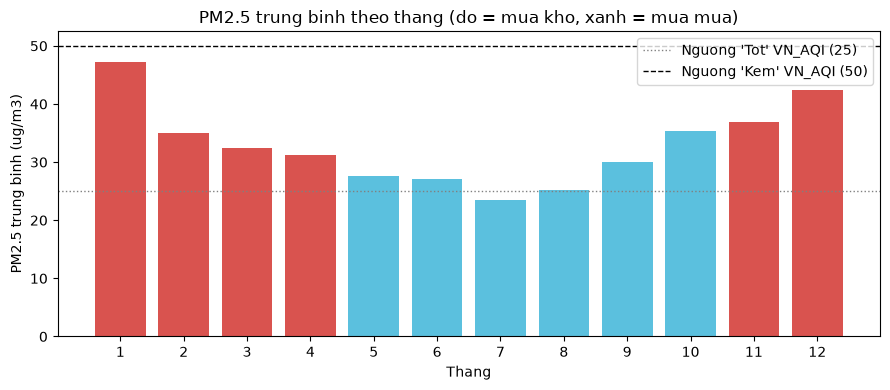

In [4]:
# groupby: chia du lieu theo nhom (mua / thang), tinh thong ke rieng cho tung nhom
print(df.groupby("mua")["pm25"].describe().round(2))

theo_thang = df.groupby("month")["pm25"].agg(["mean", "std", "count"]).round(2)
theo_thang.columns = ["PM25_TB", "PM25_Std", "So_ngay"]
print(theo_thang)

# Bieu do cot theo thang: do = mua kho (11-4), xanh = mua mua
fig, ax = plt.subplots(figsize=(9, 4))
mau = ["#d9534f" if m in [11, 12, 1, 2, 3, 4] else "#5bc0de" for m in theo_thang.index]
ax.bar(theo_thang.index, theo_thang["PM25_TB"], color=mau)
ax.axhline(25, color="gray", linestyle=":", linewidth=1, label="Nguong 'Tot' VN_AQI (25)")
ax.axhline(50, color="black", linestyle="--", linewidth=1, label="Nguong 'Kem' VN_AQI (50)")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Thang")
ax.set_ylabel("PM2.5 trung binh (ug/m3)")
ax.set_title("PM2.5 trung binh theo thang (do = mua kho, xanh = mua mua)")
ax.legend()
plt.tight_layout()
plt.savefig("../01_Data/bieu_do_pm25_theo_thang.png", dpi=120)
plt.show()

### Kết luận — mùa nào, tháng nào cần cảnh báo

- **Theo mùa:** PM2.5 trung bình **mùa khô 37,2 µg/m³** so với **mùa mưa 27,9 µg/m³** → mùa khô cao hơn khoảng **33%**. Các đơn vị nên tăng cường cảnh báo/chuẩn bị trong mùa khô (tháng 11–4).
- **Theo tháng:** nặng nhất **tháng 1 (TB 47,2 µg/m³)**, nhẹ nhất **tháng 7 (TB 23,5 µg/m³)**. Gợi ý theo ngành: du lịch/sự kiện ngoài trời cân nhắc khi lên lịch vào tháng 1; y tế tăng truyền thông bệnh hô hấp trước và trong tháng 1; bán khẩu trang/máy lọc không khí đẩy chiến dịch *trước* tháng 1.

*(Đây mới là quan sát mô tả; GĐ 3 sẽ kiểm định xem chênh lệch có ý nghĩa thống kê hay chỉ là ngẫu nhiên.)*

## 6. Bảng tổng hợp toàn bộ biến số — lưu lại cho báo cáo

Tính cùng lúc mean/median/std/CV/skewness/kurtosis cho **PM2.5 + 6 biến X** (`temperature`, `humidity`, `wind`, `rain`, `pbl_sang_m`, `ap_suat`) thay vì làm tay từng cột — đây là bảng đưa thẳng vào báo cáo mục "Thống kê mô tả".

*(2 biến `pbl_sang_m`, `ap_suat` mới thêm sau khi test hồi quy ở notebook 03 cho thấy có ích — bổ sung vào đây để thống kê mô tả cũng phủ đủ các biến chính thức dùng trong mô hình.)*

In [5]:
bien_can_thong_ke = ["pm25", "temperature", "humidity", "wind", "rain", "pbl_sang_m", "ap_suat"]

ket_qua = []
for ten in bien_can_thong_ke:
    x = df[ten]
    ket_qua.append({
        "Bien": ten,
        "Mean": round(x.mean(), 2),
        "Median": round(x.median(), 2),
        "Std": round(x.std(), 2),
        "CV (%)": round(x.std() / x.mean() * 100, 1),
        "Skewness": round(stats.skew(x), 3),
        "Kurtosis": round(stats.kurtosis(x), 3),
        "Min": round(x.min(), 2),
        "Max": round(x.max(), 2),
    })

bang_tk = pd.DataFrame(ket_qua)
bang_tk.to_csv("../01_Data/bang_thong_ke_mo_ta.csv", index=False)
print("Da luu: ../01_Data/bang_thong_ke_mo_ta.csv")
bang_tk

Da luu: ../01_Data/bang_thong_ke_mo_ta.csv


,Bien,Mean,Median,Std,CV (%),Skewness,Kurtosis,Min,Max
0,pm25,32.38,30.3,11.29,34.9,1.122,2.040,11.30,92.80
1,temperature,29.05,29.0,1.26,4.3,0.527,0.404,26.20,34.10
2,humidity,55.13,55.2,6.26,11.4,-0.168,-0.318,38.50,72.40
3,wind,13.31,13.0,3.30,24.8,0.433,-0.015,4.40,23.40
4,rain,6.12,2.2,7.98,130.4,1.711,3.027,0.00,45.70
5,pbl_sang_m,242.68,195.0,164.78,67.9,0.909,0.140,17.86,832.86
6,ap_suat,1008.79,1008.7,1.87,0.2,0.334,0.037,1003.80,1014.10


### Kết luận — biến nào biến động mạnh nhất

`rain` có hệ số biến thiên CV cao nhất (**130,4%**) — tức dao động mạnh nhất giữa các ngày. Nhưng **CV cao không đồng nghĩa ảnh hưởng mạnh đến PM2.5**: phải chờ hệ số hồi quy ở GĐ3 mới kết luận được (câu ③).

## 7. TÓM TẮT — GĐ 2 đã trả lời được gì cho câu hỏi kinh doanh

1. **7,0%** số ngày ở mức cần cảnh báo (*Kém* trở lên).
2. Mùa khô ô nhiễm nặng hơn mùa mưa khoảng **33%** (37,2 so với 27,9 µg/m³).
3. Tháng nặng nhất: **tháng 1** (47,2); nhẹ nhất: **tháng 7** (23,5).
4. Biến thời tiết dao động mạnh nhất: `rain` (CV 130,4%) — chỉ là gợi mở cho câu ③.

**Lưu ý:** đây mới là kết luận từ *thống kê mô tả* (quan sát xu hướng). Câu ② và ③ ở GĐ3 sẽ kiểm định xem các khác biệt này có ý nghĩa thống kê hay không, và dùng hồi quy để tìm nhân tố ảnh hưởng mạnh nhất.

# PHẦN MỞ RỘNG: số liệu và hình của báo cáo Word

Báo cáo Word (`Bao_cao_phan_tich_PM25_HCM.docx`) dùng thêm một số con số và hình mà phần chính ở trên chưa tạo ra. Phần này tính chúng và lưu vào `../01_Data/bao_cao/`: số liệu ở `so_lieu_bao_cao.json`, hình ở các file `hinhN_*.png`. Chạy lại là ra đúng số và hình trong báo cáo. Ba notebook 02, 03, 04 cùng ghi vào một file JSON, mỗi notebook thêm phần của mình.

**Hình của báo cáo nằm ở đâu** (số "Hình" là số trong báo cáo Word, khác số trong tên file):

| Hình | File ảnh | Mục trong phần này |
|---|---|---|
| Hình 1 | `hinh1_ty_le_theo_thang.png` | mục 1, ô vẽ hình |

Các hình còn lại: Hình 2–9 ở notebook 03, Hình 10–11 ở notebook 04.

Chạy phần này **sau** phần chính ở trên, không chen giữa (ô đầu nạp lại `df` và các tên dùng chung).


In [6]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
warnings.filterwarnings("ignore")
OUT = "../01_Data/bao_cao"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
XANH, CAM, DO, XAM = "#2E75B6", "#E07B39", "#C0392B", "#7F7F7F"

df = pd.read_csv("../01_Data/aqi_hcm_daily.csv", parse_dates=["date"])
N = len(df)
JSON_BC = f"{OUT}/so_lieu_bao_cao.json"
R = json.load(open(JSON_BC, encoding="utf-8")) if os.path.exists(JSON_BC) else {}   # so lieu cho bao cao: moi notebook ghi them phan cua minh vao cung 1 file JSON
Y = "kem_tro_len"

def py(v):
    # doi numpy -> kieu Python de ghi JSON
    if isinstance(v, dict): return {str(k): py(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)): return [py(x) for x in v]
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating,)): return None if np.isnan(v) else float(v)
    if isinstance(v, (pd.Timestamp,)): return str(v.date())
    return v

print("So dong:", N, "|", df.date.min().date(), "->", df.date.max().date())

So dong: 657 | 2024-11-19 -> 2026-10-19


## 1. Mức chung và lịch theo tháng (mục 2 của báo cáo)

Ô đầu tính số liệu rồi ghi vào JSON; ô sau vẽ **Hình 1**.

In [7]:
pm = df.pm25
R["n"] = N
R["tu_ngay"], R["den_ngay"] = str(df.date.min().date()), str(df.date.max().date())
R["pm_tb"], R["pm_median"], R["pm_skew"] = pm.mean(), pm.median(), stats.skew(pm)
R["pm_min"], R["pm_max"] = pm.min(), pm.max()
R["pm_iqr"] = pm.quantile(.75) - pm.quantile(.25)
R["ty_le"] = {"tren15": (pm > 15).mean() * 100, "tren25": (pm > 25).mean() * 100, "kem_tro_len": df[Y].mean() * 100,
              "tren80": (pm > 80).mean() * 100}
R["so_ngay"] = {"tren15": int((pm > 15).sum()), "tren25": int((pm > 25).sum()), "kem_tro_len": int(df[Y].sum()), "tren80": int((pm > 80).sum())}
R["muc_vn"] = df.vn_aqi_cat.value_counts().to_dict()
R["ngay_thieu"] = int(len(pd.date_range(df.date.min(), df.date.max())) - N)

nhom_t = np.where(df.month.isin([12, 1]), "dinh", np.where(df.month.isin([5, 6, 7, 8]), "day", "trung_gian"))
R["nhom_thang"] = {g: {"n": int((nhom_t == g).sum()), "tb": df[nhom_t == g].pm25.mean(),
                       "tren25": (df[nhom_t == g].pm25 > 25).mean() * 100, "kem": df[nhom_t == g][Y].mean() * 100}
                   for g in ["dinh", "trung_gian", "day"]}
theo_thang = df.groupby("month").agg(n=("pm25", "size"), tb=("pm25", "mean"), tren25=("pm25", lambda s: (s > 25).mean() * 100), kem=(Y, lambda s: s.mean() * 100))
R["theo_thang"] = {int(m): row.to_dict() for m, row in theo_thang.iterrows()}
ym = df.groupby([df.date.dt.year, "month"]).agg(n=("pm25", "size"), tb=("pm25", "mean"))
R["thang_nam"] = {f"{y}-{m:02d}": {"n": int(r.n), "tb": r.tb} for (y, m), r in ym.iterrows()}

# ANOVA + Tukey theo thang
tk = pairwise_tukeyhsd(df.pm25, df.month, alpha=0.05)
tt = pd.DataFrame(tk._results_table.data[1:], columns=tk._results_table.data[0])
R["tukey"] = {"khac": int(tt.reject.sum()), "tong": len(tt)}
def cap(a, bs):
    s = tt[((tt.group1 == a) & tt.group2.isin(bs)) | ((tt.group2 == a) & tt.group1.isin(bs))]
    d = s.apply(lambda r: abs(r.meandiff), axis=1)
    return {"min": d.min(), "max": d.max(), "pmax": float(s["p-adj"].max())}
R["tukey_t1_vs_t5_8"] = cap(1, [5, 6, 7, 8])
R["tukey_t12_vs_t5_8"] = cap(12, [5, 6, 7, 8])
sub = tt[((tt.group1 == 10) & (tt.group2 == 11)) | ((tt.group1 == 11) & (tt.group2 == 10))]
R["tukey_t10_t11_p"] = float(sub["p-adj"].iloc[0])
nh = [df[df.month == m].pm25.values for m in sorted(df.month.unique())]
f_, p_ = stats.f_oneway(*nh)
R["anova"] = {"F": f_, "p": p_}

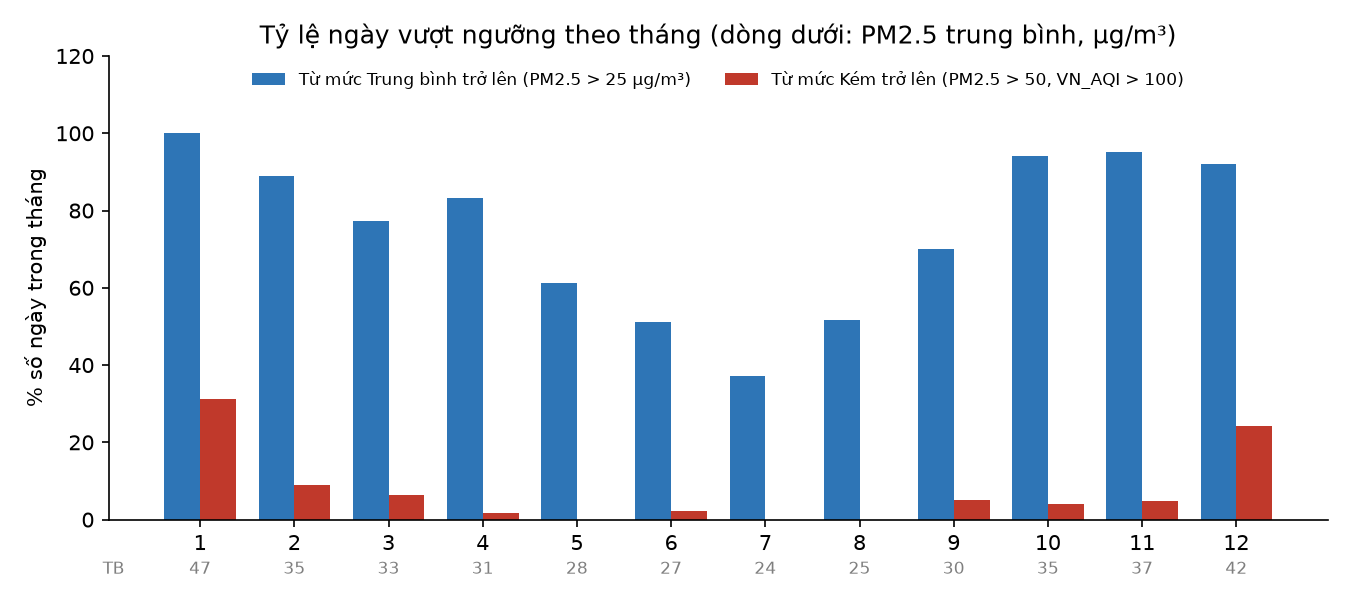

In [8]:
# Hinh 1 cua bao cao (file hinh1_ty_le_theo_thang.png): ty le ngay theo thang
fig, ax = plt.subplots(figsize=(9, 4))
th = np.arange(1, 13); w = 0.38
ax.bar(th - w / 2, theo_thang.tren25, w, color=XANH, label="Từ mức Trung bình trở lên (PM2.5 > 25 µg/m³)")
ax.bar(th + w / 2, theo_thang.kem, w, color=DO, label="Từ mức Kém trở lên (PM2.5 > 50, VN_AQI > 100)")
for t, v in zip(th, theo_thang.tb):
    ax.text(t, -14, f"{v:.0f}", ha="center", fontsize=8, color=XAM)
ax.text(0.2, -14, "TB", ha="right", fontsize=8, color=XAM)
ax.set_xticks(th); ax.set_ylim(0, 120); ax.set_ylabel("% số ngày trong tháng")
ax.set_title("Tỷ lệ ngày vượt ngưỡng theo tháng (dòng dưới: PM2.5 trung bình, µg/m³)")
ax.legend(loc="upper center", ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.savefig(f"{OUT}/hinh1_ty_le_theo_thang.png", dpi=150); plt.close(); display(Image(f"{OUT}/hinh1_ty_le_theo_thang.png"))

## Lưu số liệu cho báo cáo

In [9]:
with open(JSON_BC, "w", encoding="utf-8") as f:
    json.dump(py(R), f, ensure_ascii=False, indent=1)
print("Da luu:", JSON_BC, "| so khoa:", len(R))
print("Cac hinh:", sorted(x for x in os.listdir(OUT) if x.endswith(".png")))


Da luu: ../01_Data/bao_cao/so_lieu_bao_cao.json | so khoa: 77
Cac hinh: ['hinh10_chon_mo_hinh.png', 'hinh11_huong_gio.png', 'hinh1_ty_le_theo_thang.png', 'hinh2_rieng_vs_chung.png', 'hinh3_lich_vs_thoi_tiet.png', 'hinh4_kiem_soat_thang.png', 'hinh5_phan_du_theo_thang.png', 'hinh6_chuoi_thoi_gian.png', 'hinh7_auc_bo_bien.png', 'hinh8_thong_gio_theo_nhom.png', 'hinh9_them_tung_nhom.png']
